In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('online_retail_sample.csv')   # for real data use the .csv version of Online Retail
print('Shape:', df.shape)
print(df.isnull().sum())
df.head()

Shape: (10183, 8)
InvoiceNo        0
StockCode        0
Description      0
Quantity         0
InvoiceDate      0
UnitPrice        0
CustomerID     250
Country          0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,500001,P114,WHITE HANGING HEART,3,12/06/2011 00:00,12.22,12001.0,United Kingdom
1,500002,P115,WHITE HANGING HEART,1,11/23/2011 00:00,7.06,12001.0,United Kingdom
2,500003,P144,WHITE HANGING HEART,4,10/15/2011 00:00,2.59,12001.0,United Kingdom
3,500003,P139,WHITE HANGING HEART,3,10/15/2011 00:00,8.23,12001.0,United Kingdom
4,500003,P135,WHITE HANGING HEART,3,10/15/2011 00:00,11.33,12001.0,United Kingdom


In [2]:
n0 = len(df)
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df = df.drop_duplicates()
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
print(f'Rows: {n0} -> {len(df)}  | Customers: {df.CustomerID.nunique()}')

Rows: 10183 -> 9799  | Customers: 600


In [3]:
orders = df.groupby(['CustomerID', 'InvoiceNo'])['TotalPrice'].sum().reset_index()
print('Average order (purchase) value :', round(orders['TotalPrice'].mean(), 2))
freq = orders.groupby('CustomerID')['InvoiceNo'].nunique()
print('Average purchase frequency     :', round(freq.mean(), 2), 'orders per customer')
clv = df.groupby('CustomerID')['TotalPrice'].sum()
print('Average customer lifetime value:', round(clv.mean(), 2), '(historical total spend)')
print('Median CLV                     :', round(clv.median(), 2))
clv.describe()

Average order (purchase) value : 57.77
Average purchase frequency     : 6.78 orders per customer
Average customer lifetime value: 391.66 (historical total spend)
Median CLV                     : 151.42


count     600.0000
mean      391.6633
std       576.4770
min         1.0400
25%        36.7725
50%       151.4150
75%       410.8750
max      2947.2100
Name: TotalPrice, dtype: float64

In [4]:
snapshot = df['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')).reset_index()
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,600.000000,600.000000,600.000000,600.0000
mean,12300.500000,133.306667,6.780000,391.6633
std,173.349358,100.132313,7.250463,576.4770
min,12001.000000,1.000000,1.000000,1.0400
25%,12150.750000,49.000000,1.000000,36.7725
50%,12300.500000,103.500000,3.500000,151.4150
75%,12450.250000,218.250000,9.000000,410.8750
max,12600.000000,551.000000,29.000000,2947.2100


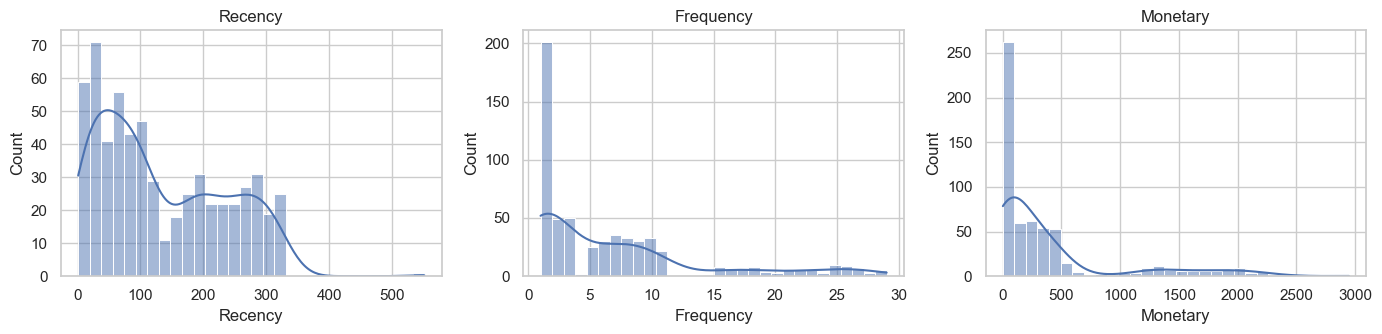

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm[c], bins=30, ax=a, kde=True); a.set_title(c)
plt.tight_layout(); plt.show()

In [6]:
X = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=['Recency', 'Frequency', 'Monetary']).describe().round(2)

,Recency,Frequency,Monetary
count,600.00,600.00,600.00
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-3.49,-1.10,-2.58
25%,-0.52,-1.10,-0.78
50%,0.16,-0.19,0.09
75%,0.84,0.73,0.70
max,1.69,1.98,1.92


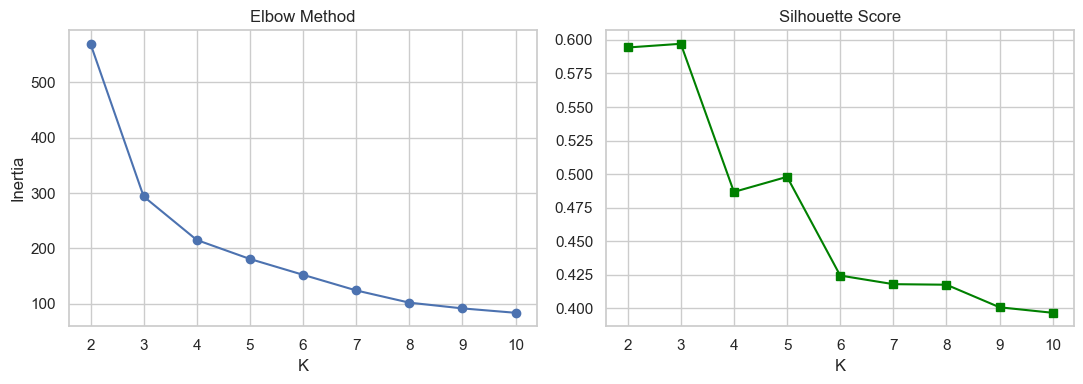

Best K by silhouette: 3


In [7]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow Method'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia')
ax[1].plot(ks, sil, 's-', color='green'); ax[1].set_title('Silhouette Score'); ax[1].set_xlabel('K')
plt.tight_layout(); plt.show()
print('Best K by silhouette:', list(ks)[int(np.argmax(sil))])

In [8]:
K = 4   # change after looking at the elbow / silhouette plots
km = KMeans(n_clusters=K, n_init=10, random_state=42)
rfm['Cluster'] = km.fit_predict(X_scaled)
print('Silhouette score:', round(silhouette_score(X_scaled, rfm['Cluster']), 3))
rfm.head()

Silhouette score: 0.487


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12001,3,27,1822.83,2
1,12002,23,18,1525.42,2
2,12003,7,19,1304.06,2
3,12004,18,19,1441.40,2
4,12005,3,15,1166.66,2


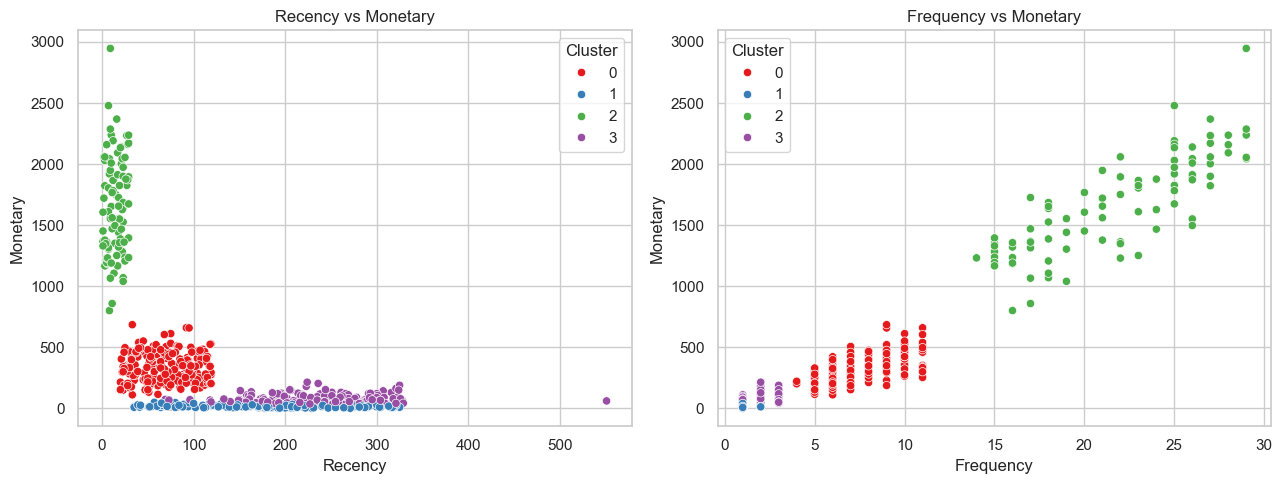

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster', palette='Set1', ax=ax[0])
ax[0].set_title('Recency vs Monetary')
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Cluster', palette='Set1', ax=ax[1])
ax[1].set_title('Frequency vs Monetary')
plt.tight_layout(); plt.show()

In [10]:
profile = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')).round(1)

# rank clusters by a simple score: high Frequency + high Monetary + LOW Recency
z = (profile[['Avg_Frequency', 'Avg_Monetary']] - profile[['Avg_Frequency', 'Avg_Monetary']].mean()) / profile[['Avg_Frequency', 'Avg_Monetary']].std()
zr = (profile['Avg_Recency'] - profile['Avg_Recency'].mean()) / profile['Avg_Recency'].std()
score = z.sum(axis=1) - zr
order = score.sort_values(ascending=False).index
names = ['Champions', 'Loyal / Potential', 'At Risk', 'Lost / Low Value']
profile['Segment'] = ''
for i, c in enumerate(order):
    profile.loc[c, 'Segment'] = names[i] if K == 4 and i < 4 else f'Segment {i+1}'
rfm['Segment'] = rfm['Cluster'].map(profile['Segment'])
profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Segment
Cluster,,,,,
0,209,70.2,7.9,339.6,Loyal / Potential
1,150,185.4,1.1,18.4,At Risk
2,90,14.8,21.7,1661.7,Champions
3,151,239.5,2.0,77.5,Lost / Low Value


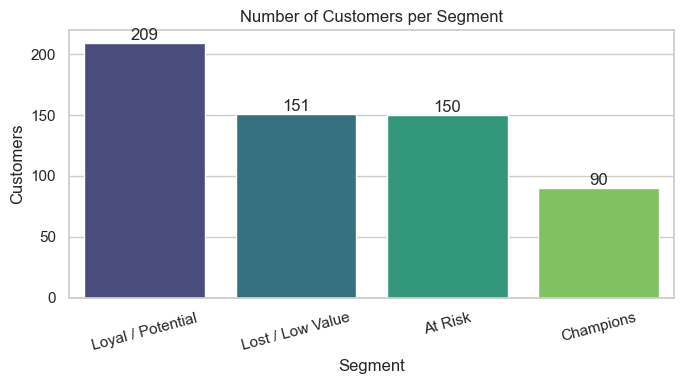

In [11]:
counts = rfm['Segment'].value_counts()
plt.figure(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, palette='viridis')
for i, v in enumerate(counts.values): plt.text(i, v, str(v), ha='center', va='bottom')
plt.title('Number of Customers per Segment'); plt.ylabel('Customers'); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

In [12]:
rfm.to_csv('customer_segments.csv', index=False)
print('Saved customer_segments.csv')

Saved customer_segments.csv
